# PCA com classificação: guia passo a passo

**O que você vai aprender:** entender o problema, conhecer os dados, separar uma parte para conferir o resultado, preparar as colunas, treinar, comparar e interpretar.

Leia uma célula por vez. Antes de executar, tente responder: “o que entra aqui e o que sai?”. Os dados deste exemplo são didáticos; os números não são uma regra para todos os exercícios.

**Palavras úteis:** *atributos* são as colunas usadas para prever; *alvo* é a resposta que queremos descobrir; *treino* é a parte usada para aprender; *teste* é a parte guardada para conferir o resultado no fim.

## Antes do código: entendendo o caminho

**1. Qual é a pergunta?** Em regressão queremos prever um número, como gasto. Em classificação queremos escolher uma categoria, como “houve evento” ou “não houve”. Em agrupamento buscamos semelhanças sem uma resposta pronta. Diga isso em uma frase antes de escolher o algoritmo.

**2. O que são X e y?** `X` é uma tabela: linhas são casos, colunas são informações conhecidas no momento da previsão. `y` é a resposta de cada linha. Se uma coluna só aparece depois do resultado, ela não pode entrar em `X`: seria como olhar o gabarito.

**3. Por que guardar um teste?** O algoritmo pode se sair bem nos exemplos que já viu e falhar nos novos. Guardamos alguns casos e evitamos usá-los para escolher colunas, parâmetros ou modelos. A validação cruzada usa apenas o treino para comparar opções.

**4. O que faz o pipeline?** Ele guarda a receita completa: preencher dados ausentes, converter categorias, ajustar escalas quando necessário e treinar o modelo. Quando essa receita é testada em uma parte da validação, seus ajustes são aprendidos apenas na parte de treino daquela rodada.

**5. Como ler uma métrica?** Uma métrica resume um aspecto do erro. Ela não responde sozinha se o modelo é útil. Compare com o baseline, veja os tipos de erro e pense no custo real de errar. Uma diferença pequena entre médias de validação pode mudar em outra amostra.


## Fundamentos estatísticos para interpretar o resultado

**População e amostra.** População é o conjunto de casos sobre o qual gostaríamos de concluir. Amostra são as linhas disponíveis. Um teste em 140 pessoas descreve o desempenho nessas pessoas; é uma estimativa do que pode ocorrer em outras semelhantes, não uma garantia. Se o modo de coletar os dados favorece um grupo, uma divisão aleatória não corrige esse problema.

**Média, mediana e dispersão.** A média soma os valores e divide pela quantidade; é sensível a extremos. A mediana é o valor central depois de ordenar; resiste mais a extremos. O desvio padrão descreve o espalhamento em torno da média. Antes de tratar um valor extremo, investigue se é erro de registro ou um caso real importante.

**Correlação.** Resume associação linear entre duas variáveis. Perto de 1 indica que tendem a subir juntas; perto de -1, que uma tende a cair quando a outra sobe; perto de 0 não descarta relações curvas. Correlação não demonstra causa. Também pode mudar quando analisamos subgrupos.

**Incerteza e validação.** A média dos folds da validação cruzada resume vários treinos; o desvio entre folds mostra quanto os resultados variaram nessas divisões. Ele não é um intervalo de confiança. Ajustar muitos parâmetros e escolher o maior score pode produzir otimismo: por isso mantemos o teste separado até o final. Em dados temporais, a validação precisa respeitar a ordem do tempo.


## Estatística e geometria em dados sem rótulo

**Distância e escala.** Agrupamentos dependem de quão próximos os pontos parecem. Se uma coluna varia de 0 a 1 e outra de 0 a 10000, a segunda pode dominar a distância; a padronização muda a geometria. Isso é uma escolha de análise, não uma verdade neutra.

**Silhouette.** Para um ponto, comparamos a distância média até seu próprio grupo com a distância média até o grupo vizinho mais próximo. O índice vai de -1 a 1: perto de 1 indica boa separação; perto de 0, fronteira; negativo pode indicar associação estranha. A média resume a amostra, mas favorece certas formas de grupo. No DBSCAN, pontos marcados como ruído são excluídos do cálculo do notebook; por isso também mostramos a cobertura.

**PCA e variância.** Variância mede espalhamento. O PCA procura direções que preservem muito desse espalhamento; “95% de variância explicada” quer dizer que os componentes retêm 95% da variação medida nesse treino, não que acertam 95% das previsões. É preciso avaliar a tarefa final separadamente.


## Ideia do algoritmo, sem fórmula

PCA cria novas colunas a partir de combinações das colunas originais. A primeira tenta preservar o máximo possível da variação dos dados; as próximas acrescentam outras direções.

Preservar variação não é a mesma coisa que preservar a informação que ajuda a prever o alvo. Por isso comparamos o modelo com e sem PCA por validação.

Padronizamos antes porque colunas com unidades maiores poderiam dominar o cálculo. Os componentes novos podem ser mais difíceis de explicar que as colunas originais.

**Experimento mental:** se uma coluna passar a ter valores dez vezes maiores, o que pode mudar? Se o treino tiver poucos exemplos, o que pode acontecer? Depois de executar, compare suas respostas com os resultados.

## 1. Objetivo
PCA reduz dimensionalidade criando eixos que explicam variância. Não é um classificador e variância alta não garante melhor previsão. Vamos comparar regressão logística com e sem PCA dentro da validação, mantendo o teste reservado.

### Lendo esta célula
`X` contém as informações e `y` contém a resposta. `train_test_split` separa linhas para treino e teste; `test_size=0.2` guarda 20%. `random_state` permite repetir a divisão. Em classificação, `stratify=y` procura manter proporções semelhantes das classes.

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

## Guia das funções e métodos usados neste notebook

As explicações também aparecem ao lado das células que usam cada função. Use este índice quando quiser rever uma ferramenta.

**`pd.DataFrame`** — Cria uma tabela com linhas e colunas. Aqui organiza as informações de entrada; não treina nada.

**`describe`** — Calcula resumos como quantidade, média, desvio padrão, mínimo, quartis e máximo. Serve para procurar escalas e valores estranhos.

**`isna`** — Marca valores ausentes. Com `mean`, produz a fração ausente em cada coluna, porque verdadeiro conta como 1.

**`value_counts`** — Conta quantas vezes cada classe ou categoria aparece; com `normalize=True`, mostra proporções.

**`hist`** — Desenha histogramas para enxergar onde os valores se concentram e se há caudas ou extremos.

**`train_test_split`** — Separa linhas em treino e teste. O treino serve para ajustar e comparar; o teste fica guardado para a avaliação final. `stratify=y` preserva aproximadamente as proporções das classes.

**`StandardScaler`** — Aprende média e desvio padrão no treino e transforma as colunas numéricas para escalas comparáveis. É importante para distâncias, SVM e modelos com regularização.

**`Pipeline`** — Encadeia preparação e algoritmo em uma única receita. `fit` ajusta cada etapa com os dados permitidos; `predict` reaplica a mesma receita a linhas novas.

**`KFold`** — Define divisões repetidas do treino para estimar desempenho; cada parte vira validação uma vez.

**`StratifiedKFold`** — Faz as divisões repetidas mantendo aproximadamente a proporção das classes em cada parte.

**`GridSearchCV`** — Treina as combinações de parâmetros dadas, avalia cada uma nas divisões de validação e escolhe a maior média da métrica. `best_estimator_` é o pipeline vencedor reajustado em todo o treino; `best_score_` é a média de validação vencedora.

**`fit`** — Ajusta o modelo aos dados de treino. Em transformadores, aprende estatísticas como mediana e escala; em estimadores, aprende regras ou parâmetros.

**`predict`** — Gera uma resposta para cada linha. Em regressão, um número; em classificação, uma classe.

**`classification_report`** — Resume precisão, recall, F1 e suporte por classe. Suporte é a quantidade real de exemplos daquela classe.

**`fit_transform`** — Aprende os parâmetros da transformação no conjunto fornecido e já devolve os dados transformados. Na validação, deve acontecer dentro do pipeline.

**`LogisticRegression`** — Aprende um escore linear e o converte em probabilidade estimada de classe. `C` menor significa regularização mais forte.

**`DummyClassifier`** — Baseline de classificação: usa uma regra simples, como a frequência das classes, sem aprender relação entre colunas e alvo.

**`PCA`** — Cria novas colunas que preservam variação. `n_components` pode ser quantidade de componentes ou fração de variância a manter; não garante melhor previsão.

In [1]:
# Bibliotecas: trazemos ferramentas prontas para tabelas, gráficos e modelos.
import pandas as pd

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [2]:
# Bibliotecas: trazemos ferramentas prontas para tabelas, gráficos e modelos.
import matplotlib.pyplot as plt

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [3]:
from IPython.display import display

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [4]:
from sklearn.datasets import load_breast_cancer

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [6]:
from sklearn.pipeline import Pipeline

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [7]:
from sklearn.preprocessing import StandardScaler

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [8]:
from sklearn.decomposition import PCA

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [9]:
from sklearn.linear_model import LogisticRegression

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [10]:
from sklearn.dummy import DummyClassifier

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [11]:
from sklearn.metrics import balanced_accuracy_score, classification_report

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [12]:
base = load_breast_cancer(as_frame=True)

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [13]:
X, y = base.data, base.target  # Base pública incluída no sklearn; não é ferramenta clínica.

**Funções e métodos desta célula**

`train_test_split` divide as linhas em treino e teste. `test_size=0.2` guarda 20% para o teste. `random_state` repete a divisão. Em classificação, `stratify=y` procura preservar a proporção de cada classe nos dois conjuntos. A função devolve quatro objetos: X de treino, X de teste, y de treino e y de teste.

In [14]:
# Guardamos uma parte dos dados; ela será usada só na avaliação final.
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

**Funções e métodos desta célula**

`describe` calcula resumos como média, quartis e extremos, conforme o tipo de coluna.

In [15]:
display(X_treino.describe())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000,455.000000
mean,14.067213,19.247363,91.557407,648.541099,0.096167,0.103869,0.089193,0.048344,0.180618,0.062820,0.398972,1.218729,2.822550,39.243747,0.007084,0.025538,0.032552,0.011673,0.020779,0.003797,16.177226,25.647297,106.625297,869.026593,0.132329,0.254329,0.276578,0.113904,0.290865,0.083945
std,3.499380,4.405291,24.149231,344.944564,0.013458,0.053522,0.081747,0.038925,0.028074,0.007159,0.267825,0.571523,1.973475,41.763197,0.003135,0.018467,0.032370,0.006290,0.008764,0.002780,4.770020,6.225470,33.195053,552.926912,0.022550,0.159882,0.215937,0.066784,0.064624,0.018408
min,6.981000,9.710000,43.790000,143.500000,0.062510,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.635000,16.000000,74.720000,415.650000,0.086475,0.063750,0.028010,0.020220,0.161750,0.057685,0.234100,0.830500,1.597000,17.730000,0.005185,0.012745,0.014550,0.007501,0.015090,0.002214,13.010000,21.090000,83.715000,513.900000,0.115950,0.145850,0.107900,0.063390,0.249400,0.071835
50%,13.270000,18.820000,85.980000,541.800000,0.095660,0.090970,0.059990,0.032630,0.178100,0.061440,0.316300,1.077000,2.235000,24.250000,0.006369,0.020170,0.025890,0.010670,0.018700,0.003114,14.910000,25.400000,97.590000,683.400000,0.131400,0.211600,0.229800,0.097220,0.281900,0.079930
75%,15.740000,21.710000,103.700000,770.050000,0.104850,0.130100,0.132200,0.073820,0.195300,0.066250,0.468900,1.472000,3.264500,44.775000,0.008183,0.032130,0.042705,0.014600,0.023560,0.004526,18.550000,29.370000,124.950000,1033.500000,0.146200,0.336800,0.385300,0.162500,0.320100,0.092070
max,28.110000,39.280000,188.500000,2499.000000,0.144700,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,525.600000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,33.130000,49.540000,229.300000,3432.000000,0.218400,1.058000,1.252000,0.291000,0.663800,0.207500


**Funções e métodos desta célula**

`isna` marca os valores ausentes; ao tirar a média dessas marcas, obtemos a fração ausente.

In [16]:
display(X_treino.isna().sum())

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

**Funções e métodos desta célula**

`value_counts` conta ocorrências; com `normalize=True`, mostra proporções.

In [17]:
display(y_treino.value_counts())

target
1    285
0    170
Name: count, dtype: int64

**Funções e métodos desta célula**

`hist` mostra a distribuição de valores em faixas. Ajuda a perceber concentração e extremos.

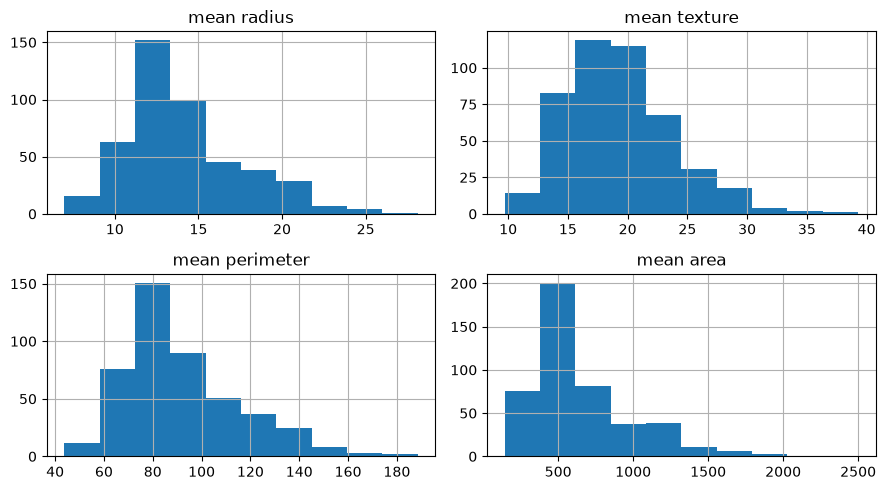

In [18]:
X_treino.iloc[:, :4].hist(figsize=(9, 5)); plt.tight_layout(); plt.show()

## 2. Preparação, baseline e seleção
A base não contém ausências. Padronização e PCA são ajustados somente dentro de cada fold. Escolhemos balanced accuracy, média do recall das classes; maior é melhor. O baseline participa da busca. `0.90` e `0.95` são frações de variância, enquanto `5` e `10` são quantidades de componentes.

### Lendo esta célula
O dicionário `candidatos` dá um nome a cada modelo e lista valores que queremos experimentar. `GridSearchCV` treina combinações em várias divisões do treino. `best_score_` é a melhor média de validação. A tabela mostra também variação entre rodadas e resultado no próprio treino; diferença grande pode sugerir sobreajuste.

**Funções e métodos desta célula**

`Pipeline` encadeia etapas. Neste guia, primeiro prepara as colunas e depois treina o algoritmo. Ao validar, cada divisão ajusta a preparação somente com seu próprio treino. `fit` aprende; `predict` usa essa receita já aprendida para gerar respostas novas.

`StandardScaler` aprende a média e o desvio padrão de cada coluna numérica no treino. Depois subtrai a média e divide pelo desvio padrão, permitindo comparar distâncias entre colunas em escalas diferentes.

In [19]:
# A preparação e o modelo andam juntos em cada teste.
pipeline = Pipeline([("escala", StandardScaler()), ("pca", "passthrough"),
                     ("modelo", LogisticRegression(max_iter=3000))])

**Funções e métodos desta célula**

`PCA` aprende novas direções que preservam variação dos dados. `n_components` pode ser a quantidade de novas colunas ou a fração de variância a manter. PCA não usa y nem garante melhor previsão.

In [20]:
grade = [
    {"pca": ["passthrough"], "modelo": [DummyClassifier(strategy="most_frequent")]},
    {"pca": ["passthrough"], "modelo__C": [0.1, 1]},
    {"pca": [PCA(svd_solver="full")], "pca__n_components": [5, 10, 0.90, 0.95], "modelo__C": [0.1, 1]}
]

**Funções e métodos desta célula**

`GridSearchCV` prepara uma busca de parâmetros. Recebe o pipeline, a grade de valores, a métrica em `scoring` e a divisão em `cv`. Ao chamar `fit`, treina cada combinação em cada divisão e escolhe a melhor média. `best_score_` é o resultado médio de validação; `best_estimator_` é o pipeline vencedor reajustado em todo o treino.

In [21]:
# Testamos combinações de parâmetros usando só o treino.
busca = GridSearchCV(pipeline, grade, scoring="balanced_accuracy",
                     cv=StratifiedKFold(3, shuffle=True, random_state=42), n_jobs=1, error_score="raise")

**O que esta célula produz:** Esta célula organiza os dados da etapa anterior para a próxima operação do exemplo.

In [22]:
# Aqui o algoritmo aprende os padrões do treino.
busca.fit(X_treino, y_treino)

**Funções e métodos desta célula**

`pd.DataFrame` cria uma tabela. Cada coluna recebe uma lista de valores e cada posição na lista forma uma linha. Aqui a tabela contém os atributos usados no modelo.

`sort_values` ordena as linhas pela coluna indicada; `ascending=False` coloca os maiores valores primeiro.

In [23]:
display(pd.DataFrame(busca.cv_results_)[["params", "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False))

,params,mean_test_score,std_test_score
8,"{'modelo__C': 1, 'pca': PCA(svd_solver='full')...",0.978895,0.008640
10,"{'modelo__C': 1, 'pca': PCA(svd_solver='full')...",0.978895,0.008640
9,"{'modelo__C': 1, 'pca': PCA(svd_solver='full')...",0.973632,0.001369
2,"{'modelo__C': 1, 'pca': 'passthrough'}",0.972462,0.006393
4,"{'modelo__C': 0.1, 'pca': PCA(svd_solver='full...",0.971878,0.013741
6,"{'modelo__C': 0.1, 'pca': PCA(svd_solver='full...",0.971878,0.013741
1,"{'modelo__C': 0.1, 'pca': 'passthrough'}",0.971825,0.007435
7,"{'modelo__C': 1, 'pca': PCA(svd_solver='full')...",0.970708,0.006993
3,"{'modelo__C': 0.1, 'pca': PCA(svd_solver='full...",0.968369,0.013059
5,"{'modelo__C': 0.1, 'pca': PCA(svd_solver='full...",0.968369,0.013059


**O que acontece nesta célula:** Mostramos o resultado em texto. Leia o número junto da métrica e da base usada; um valor isolado não diz se o modelo é útil.

In [24]:
print("Escolha pela validação:", busca.best_params_)

Escolha pela validação: {'modelo__C': 1, 'pca': PCA(svd_solver='full'), 'pca__n_components': 10}


**Funções e métodos desta célula**

`predict` recebe linhas com as mesmas colunas esperadas e devolve uma previsão por linha. Em regressão, um número; em classificação, um rótulo. O pipeline aplica a preparação antes do modelo.

In [25]:
# Só agora consultamos o teste, para o pipeline já escolhido.
pred = busca.predict(X_teste)

**O que acontece nesta célula:** Mostramos o resultado em texto. Leia o número junto da métrica e da base usada; um valor isolado não diz se o modelo é útil.

In [26]:
print("Balanced accuracy final:", balanced_accuracy_score(y_teste, pred))

Balanced accuracy final: 0.9742063492063492


**Funções e métodos desta célula**

`classification_report` devolve um resumo de precisão, recall, F1 e quantidade de exemplos por classe. Leia as linhas de cada classe antes da média.

In [27]:
print(classification_report(y_teste, pred, target_names=base.target_names))

              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



## 3. Variância explicada e interpretação
O gráfico abaixo é descritivo, calculado apenas no treino. Ele não muda a escolha já avaliada no teste. Componentes misturam atributos originais e podem dificultar interpretação.

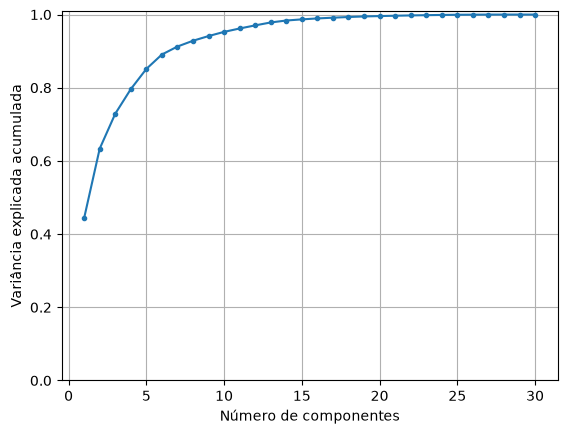

In [28]:
Z_treino = StandardScaler().fit_transform(X_treino)
pca_descritivo = PCA().fit(Z_treino)
plt.plot(range(1, X.shape[1] + 1), pca_descritivo.explained_variance_ratio_.cumsum(), marker=".")
plt.xlabel("Número de componentes"); plt.ylabel("Variância explicada acumulada")
plt.ylim(0, 1.01); plt.grid(); plt.show()

## 4. Exercícios
Compare quantidade de componentes, custo e score. Se o vencedor não usar PCA, aceite o resultado: compressão não garante melhoria. Ao trocar a base, acrescente imputação dentro do pipeline se necessário e confira o significado das classes. Este conjunto de estudo não valida uso médico.